In [1]:
import os, glob
import numpy as np
import pandas as pd
import scanpy as sc
from pygam import LinearGAM, s
import matplotlib.pyplot as plt

/home/caleb/miniconda3/envs/pygam/lib/python3.13/site-packages/numcodecs/__init__.py:106: DeprecationWarning: crc32c usage is deprecated since numcodecs v0.16.4. It is recommended to install google_crc32c instead.
  from numcodecs.checksum32 import CRC32, Adler32, JenkinsLookup3


In [2]:
pth_data = os.path.join('..', 'data')
pth_in = os.path.join(pth_data, 'modeling', 'inputs')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_fig = os.path.join('..', 'figures', 'modeling', 'modules')
pth_out = os.path.join(pth_feat, 'modules')

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'development.h5ad'))
adata.obs['t'] = adata.obs.t.astype(float); adata

AnnData object with n_obs × n_vars = 14458 × 14985
    obs: 'sample', 'celltype', 't', 'source'
    obsm: 'X_pca', 'X_umap', 'X_umap_traj'

In [ ]:
feat_fn = sorted(glob.glob(os.path.join(pth_feat, '*.csv')))
get_src = lambda fn: os.path.split(fn)[1].replace('.csv', '')
feat_dict = {get_src(fn) : pd.read_csv(fn) for fn in feat_fn}

# module signatures
g_ref = feat_dict['union'].mmusculus
for src, df_src in feat_dict.items():
    if src != 'union':
        print(src)
        g = df_src.mmusculus.copy()
        g = g.loc[g.isin(adata.var_names)]
        for _, df_group in adata.obs.groupby('source', observed = True):
            msk = adata.obs_names.isin(df_group.index)
            adata_group = adata[msk].copy()
            sc.tl.score_genes(adata_group,
                              gene_list = g,
                              score_name = src,
                              ctrl_as_ref = False,
                              gene_pool = g_ref,
                              random_state = 1234)
            adata.obs.loc[msk, src] = adata_group.obs[src]

GSE162534
GSE229103
rRNAModifications


In [5]:
def fit_gam(Y, X, n_spl, n_pts):
    GAM = LinearGAM(s(0, n_splines = n_spl))
    GAM = GAM.fit(X, scale_01(Y))
    xx = np.linspace(X.min(), X.max(), n_pts)
    return scale_01(GAM.predict(xx))

def scale_01(Y):
    return (Y - Y.min()) / (Y.max() - Y.min())

In [6]:
labels_dict = {
    'GSE162534'         : 'PS',
    'GSE229103'         : 'NMP',
    'rRNAModifications' : 'CNCC'}

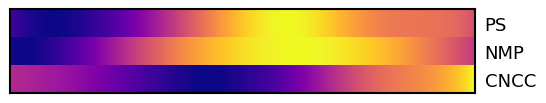

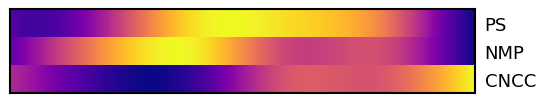

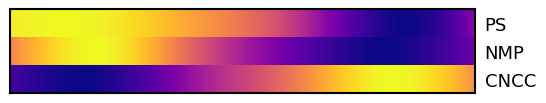

In [25]:
# signatures trends (GAMs)
n_pts, n_spl, cols = 500, 8, list(labels_dict.keys())
for src, sdf in adata.obs.groupby('source', observed = True):

    # fit GAMs
    X = np.zeros((len(cols), n_pts))
    for i, mod in enumerate(cols):
        X[i] = fit_gam(sdf[mod], sdf.t, n_spl, n_pts)

    # plot heatmap
    fig, ax = plt.subplots(1, 1, figsize = (6, 3))
    ax.imshow(X, aspect = 30, interpolation = 'nearest', cmap = 'plasma')
    yticks, yticklabels = np.arange(len(cols)), list(labels_dict.values())
    ax.set_yticks(yticks, yticklabels, fontsize = 13)
    ax.tick_params('y', left = False, labelleft = False, labelright = True)
    ax.set_xticks([])
    for sp in ax.spines.values(): sp.set_linewidth(1.5)
    fn = os.path.join(pth_fig, f'{src}.pdf')
    plt.savefig(fn, bbox_inches = 'tight')

In [26]:
# early module (PS & NMP)
early = pd.merge(feat_dict['GSE162534'], feat_dict['GSE229103'])
early.to_csv(os.path.join(pth_out, 'early.csv'), index = False)

# late module (CNCC)
late = feat_dict['rRNAModifications'].copy()
late.to_csv(os.path.join(pth_out, 'late.csv'), index = False)

# reference module (PS | NMP | CNCC)
ref = feat_dict['union'].copy()
ref.to_csv(os.path.join(pth_out, 'ref.csv'), index = False)